# Lab 6: Localization by odometry

**Diyorbek Shokirov, ID 240046**

The robot drives the digits of my ID, **46**, as straight strokes (50 % power) and 90° turns in place (40 %),
with a 200 ms stop after every move. The moves are a table (left power, right power, time); one loop sets the
motors for each move and, while the move runs, reads both encoders, computes x, y and the heading, and writes
`x,y,time` to the file. `trajectory_sim.qrs` and `trajectory_real.qrs` have the same blocks; only r and B
(0.028 m / 0.154 m for the simulated robot, 0.0375 m / 0.194 m for mine), the move times and the file name
differ. The real times were found with two short test runs on the robot.

Odometry used in the program (left wheel = encoder 3, right wheel = encoder 4, angles in degrees):

$$d = \frac{\varphi_R + \varphi_L}{2}\, R\, \frac{\pi}{180}, \qquad
\theta = \frac{\varphi_R - \varphi_L}{B}\, R\, \frac{\pi}{180}, \qquad
x \mathrel{+}= \Delta d \cos\!\left(\theta - \tfrac{\Delta\theta}{2}\right), \quad
y \mathrel{+}= \Delta d \sin\!\left(\theta - \tfrac{\Delta\theta}{2}\right)$$

In [1]:
import os
import numpy as np                  # arrays and maths
import matplotlib.pyplot as plt     # plots

if not os.path.exists('odometry_data_sim.txt'):   # only in Colab: upload the txt files first
    from google.colab import files
    uploaded = files.upload()

# every line of a log is x [m], y [m], time [ms]; unpack=True gives three separate arrays
x_s, y_s, t_s = np.loadtxt('odometry_data_sim.txt',  delimiter=',', unpack=True)   # simulator run
x_r, y_r, t_r = np.loadtxt('odometry_data_real.txt', delimiter=',', unpack=True)   # real robot run

# quick check: how many lines each log has and how long each run took
print(f'simulator: {len(t_s)} samples, {(t_s[-1] - t_s[0]) / 1000:.1f} s')
print(f'real robot: {len(t_r)} samples, {(t_r[-1] - t_r[0]) / 1000:.1f} s')

simulator: 3738 samples, 37.4 s
real robot: 211 samples, 24.3 s


## 1. Model vs real trajectory

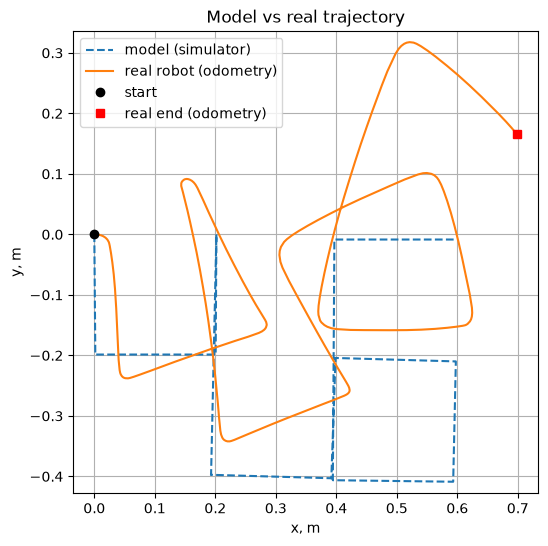

In [2]:
plt.figure(figsize=(6, 6))                                      # square picture, seen from above
plt.plot(x_s, y_s, '--', label='model (simulator)')              # dashed: the planned "46" from the simulator
plt.plot(x_r, y_r,       label='real robot (odometry)')          # solid: where the real robot thinks it drove
plt.plot(0, 0, 'ko', label='start')                              # black dot: start point
plt.plot(x_r[-1], y_r[-1], 'rs', label='real end (odometry)')    # red square: last line of the real log
plt.axis('equal'); plt.grid(True); plt.legend()                  # equal axes so the shape is not stretched
plt.xlabel('x, m'); plt.ylabel('y, m')                           # x = start direction, y = to the left
plt.title('Model vs real trajectory')
plt.show()

**What this graph shows.** The robot's path seen from above: x is the direction the robot faced at the
start, y is to its left. The dashed line is the simulator's odometry, the planned "46" with 0.2 m strokes and
right angles. The solid line is the real robot's odometry, the path the robot *thinks* it drove. The strokes of the real run have about the right length,
but after every turn they point in a slightly different direction than in the model.

## 2. Position error over time

The simulator log is resampled onto the real-robot timestamps, so both are compared at the same moments.

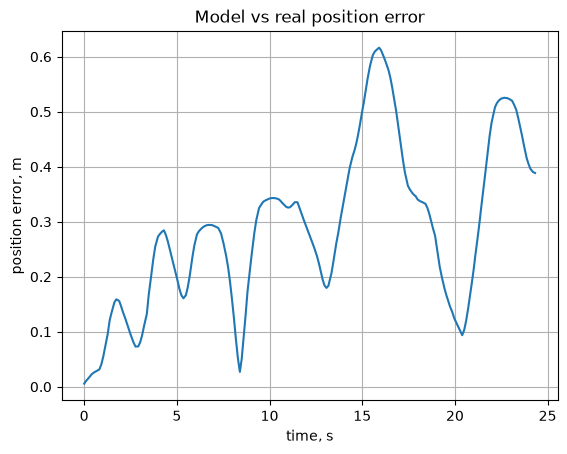

Final odometry error (sim vs real): 0.39 m
Max error: 0.62 m


In [3]:
t_s, t_r = t_s - t_s[0], t_r - t_r[0]       # both runs start at 0 ms
xs_i = np.interp(t_r, t_s, x_s)              # where the simulator was at each real-robot time
ys_i = np.interp(t_r, t_s, y_s)
err = np.hypot(x_r - xs_i, y_r - ys_i)       # distance between the two positions at the same time [m]

plt.plot(t_r / 1000, err)                    # error against time in seconds
plt.xlabel('time, s'); plt.ylabel('position error, m'); plt.grid(True)
plt.title('Model vs real position error')
plt.show()

print(f'Final odometry error (sim vs real): {err[-1]:.2f} m')   # error at the end of the run
print(f'Max error: {err.max():.2f} m')                           # largest error during the run

**What this graph shows.** For every moment of the real run, the distance between where the simulator was
and where the real robot's odometry was at the same time. 0 m means both are at the same place. The error grows
when the real heading drifts away from the model; it is largest (0.62 m) at about 16 s and 0.39 m at the end.
The real program uses shorter move times (24 s instead of 37 s in the simulator), so part of the difference at
equal time comes from the timing, not only from the position.

## 3. Measured end point

Before the run I marked on the floor the point under the middle of the robot (between the wheels) and its start
direction. After the run I measured where that point stopped: x along the start direction, y to the left.

In [4]:
x_meas, y_meas = 0.62, -0.09    # tape measurement, m (x forward from the start mark, y to the left)

# the last line of the real log is where the robot THINKS it stopped; the tape is where it REALLY stopped
print(f'odometry end point: x = {x_r[-1]:.2f} m, y = {y_r[-1]:.2f} m')
print(f'measured end point: x = {x_meas:.2f} m, y = {y_meas:.2f} m')
print(f'odometry error vs reality: {np.hypot(x_r[-1] - x_meas, y_r[-1] - y_meas):.2f} m')   # distance between them

odometry end point: x = 0.70 m, y = 0.17 m
measured end point: x = 0.62 m, y = -0.09 m
odometry error vs reality: 0.27 m


## 4. Conclusions

The real robot matches the model only at the start; after the first turns the strokes come out tilted, and the
error reaches 0.62 m at about 16 s and ends at 0.39 m. The main cause is heading error: the turns are timed, not
measured, so each "90°" turn is a bit off and every later stroke goes in the wrong direction, which makes the
error grow over time. The odometry end point (0.70, 0.17) m is also 0.27 m from the measured one
(0.62, −0.09) m, which points to wheel slip in the turns or a wrong B that the encoders cannot detect. The robot
does not know it is wrong, because it only counts wheel rotations and has no external reference.